In [380]:
import torch
from torch import linalg, optim
import matplotlib.pyplot as plt

from utils import *

# Exemple venant du cours

On essaie (sans grand succès) de reproduire l'exemple de la page 29 du cours n°4 :

On minimise $F(U) = \frac{1}{4} \| UU^\top - M^\star \|^2_{F}$ avec
$M^\star = Q \Lambda Q^\top $, $Q$ orthogonale et $\Lambda$ diagonale de coeffs
diagonaux strictement positifs.

In [381]:
#torch.manual_seed(123)

r = 8
L = torch.diag(torch.tensor([100.] * (r//2) + [1.] * (r//2))) # condition number = 100
Q, _ = linalg.qr(torch.randn(r, r))
M = Q @ L @ Q.T

def F(U):
    return 0.25 * linalg.matrix_norm(U @ U.T - M, ord='fro') ** 2

In [382]:
names = ("SGD", "Spectral GD")

variables = [torch.randn(r, r, requires_grad=True) for _ in names]

optimizers = [
    optim.SGD([variables[0]], lr=0.005),
    spectral_GD(variables[1], lr=0.01)
]

In [383]:
losses = [[] for _ in names]

epochs = 1000
for _ in range(epochs):
    for U, opt, loss in zip(variables, optimizers, losses):
        loss_value = F(U)
        loss.append(loss_value.item())
        loss_value.backward()
        opt.step()
        opt.zero_grad()

for name, loss in zip(names, losses):
    print(f"{name}: final loss = {loss[-1]}")

SGD: final loss = 6.908091449986387e-07
Spectral GD: final loss = 0.0376754030585289


Même réglant les hyperparamètres au mieux pour les deux méthodes, je n'arrive pas
à reproduire les résultats du cours. J'ai l'impression que le gradient spectral
est beaucoup plus lente que la descente de gradient classique.

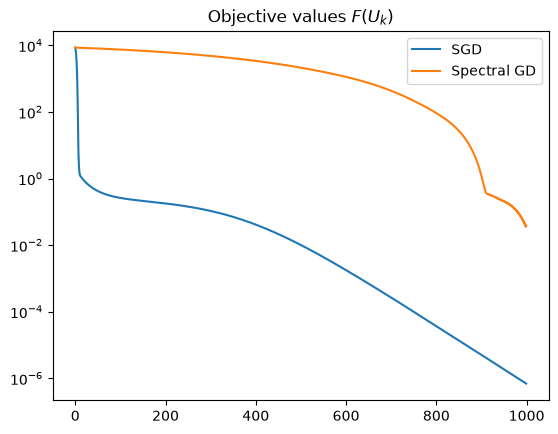

In [384]:
fig, ax = plt.subplots()
ax.set_title("Objective values $F(U_k)$")
ax.set_yscale('log')
for name, loss in zip(names, losses):
    ax.plot(loss, label=name)
ax.legend()

plt.show()